# TP 3 — Prompting

**Même problème que les TP précédents** : à partir d'une réplique de *Tiny Shakespeare*, retrouver **quel personnage la prononce** (5 classes : `DUKE VINCENTIO`, `GLOUCESTER`, `MENENIUS`, `PETRUCHIO`, `ROMEO`).

Cette fois, **aucun entraînement** : on décrit la tâche à un LLM dans un *prompt*. Le pipeline suit les 4 étapes de la consigne :

| # | Étape | Dans ce notebook |
|---|---|---|
| 1 | **Prompting** | conception de 3 prompts (zero-shot, zero-shot + contexte, few-shot) |
| 2 | **Modèle LLM** | un modèle ouvert chargé localement (par défaut) ou une API |
| 3 | **Sortie générée** | sortie JSON, parsing, taux de sorties invalides |
| 4 | **Évaluation** | mêmes métriques et **même jeu de test** que les TP1/TP2, comparaison avec la baseline |

**Protocole** (comme au cours) : on compare les prompts sur la **validation**, on retient le meilleur, puis on le lance **une seule fois** sur le **test**.

## 0. Mettre en place l'environnement

In [1]:
!pip install -q -U transformers accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 85.8 MB/s eta 0:00:00


In [2]:
import re
import json
import time
import random
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 100)

print("Environnement prêt.")

Environnement prêt.


## 1. Données : même corpus, même découpage que les TP précédents

On reconstruit **exactement** le même jeu de test (mêmes filtres, même `random_state`, même stratification) pour que les scores soient comparables avec ceux du TP1/TP2. Le **train** ne sert plus à entraîner un modèle, mais à (a) choisir les exemples du prompt *few-shot* et (b) réentraîner la baseline TF-IDF de comparaison.

In [3]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
texte = urllib.request.urlopen(URL).read().decode("utf-8")


def parser_repliques(txt: str) -> pd.DataFrame:
    """Découpe le corpus en répliques (locuteur, texte)."""
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


N_LOCUTEURS, MIN_MOTS = 5, 5
df = parser_repliques(texte)
df["n_mots"] = df["replique"].str.split().str.len()
top_locuteurs = df["locuteur"].value_counts().head(N_LOCUTEURS).index.tolist()

donnees = (
    df[df["locuteur"].isin(top_locuteurs)]
      .query("n_mots >= @MIN_MOTS")
      .loc[:, ["replique", "locuteur"]]
      .reset_index(drop=True)
)

# Split stratifié 70 / 15 / 15 (identique au TP2)
X_train, X_temp, y_train, y_temp = train_test_split(
    donnees["replique"], donnees["locuteur"], test_size=0.30,
    stratify=donnees["locuteur"], random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

CANDIDATS = sorted(y_train.unique())
print(f"{len(donnees)} répliques -> train {len(X_train)} | val {len(X_val)} | test {len(X_test)}")
print("Classes :", CANDIDATS)
print(f"Plancher de l'accuracy (classe majoritaire) : {y_test.value_counts(normalize=True).max():.1%}")

761 répliques -> train 532 | val 114 | test 115
Classes : ['DUKE VINCENTIO', 'GLOUCESTER', 'MENENIUS', 'PETRUCHIO', 'ROMEO']
Plancher de l'accuracy (classe majoritaire) : 26.1%


## 2. Le modèle LLM

Deux options, au choix via `BACKEND` :

- **`"hf"`** (par défaut) : un modèle **à poids ouverts** (`Qwen2.5-3B-Instruct`) chargé et exécuté dans Colab. Gratuit, sans clé ; prévoir un **GPU** (*Exécution → Modifier le type d'exécution → T4*). Avec un modèle plus petit (`Qwen/Qwen2.5-1.5B-Instruct`) tout va plus vite mais la qualité baisse.
- **`"anthropic"`** : appel d'une **API hébergée** (nécessite une clé `ANTHROPIC_API_KEY`, à placer dans les *Secrets* de Colab). Plus simple côté infra, mais payant et dépendant du fournisseur.

Dans les deux cas, le reste du notebook utilise la même fonction `generer_batch(messages, temperature, max_new_tokens)`. On génère à **température 0** (décodage glouton) : pour de la classification, on veut une sortie stable et reproductible.

In [4]:
# [BACKEND]
BACKEND = "hf"                              # "hf" ou "anthropic"
MODEL_HF = "Qwen/Qwen2.5-3B-Instruct"       # modèle ouvert (backend "hf")
MODEL_API = "claude-haiku-5-5"              # modèle API (backend "anthropic")

if BACKEND == "hf":
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM

    print("GPU disponible :", torch.cuda.is_available())
    tokenizer = AutoTokenizer.from_pretrained(MODEL_HF, padding_side="left")   # padding à gauche pour la génération
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    modele = AutoModelForCausalLM.from_pretrained(
        MODEL_HF,
        dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
        device_map="auto",
    )
    modele.eval()

    def generer_batch(messages_list, temperature=0.0, max_new_tokens=30, batch_size=8):
        """messages_list : liste de conversations [{role, content}, ...] -> liste de textes générés."""
        sorties = []
        for i in range(0, len(messages_list), batch_size):
            lot = messages_list[i:i + batch_size]
            textes = [tokenizer.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in lot]
            enc = tokenizer(textes, return_tensors="pt", padding=True).to(modele.device)
            params = dict(max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id)
            if temperature > 0:
                params.update(do_sample=True, temperature=temperature, top_p=0.95)
            else:
                params.update(do_sample=False)
            with torch.no_grad():
                sortie = modele.generate(**enc, **params)
            sortie = sortie[:, enc["input_ids"].shape[1]:]          # on ne garde que la partie générée
            sorties += tokenizer.batch_decode(sortie, skip_special_tokens=True)
        return [s.strip() for s in sorties]

    def compter_tokens(messages):
        texte = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        return len(tokenizer(texte)["input_ids"])

elif BACKEND == "anthropic":
    import os, subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "anthropic"], check=True)
    from anthropic import Anthropic
    try:
        from google.colab import userdata
        cle = userdata.get("ANTHROPIC_API_KEY")
    except Exception:
        cle = os.environ.get("ANTHROPIC_API_KEY")
    client = Anthropic(api_key=cle)

    def generer_batch(messages_list, temperature=0.0, max_new_tokens=30, batch_size=None):
        sorties = []
        for msgs in messages_list:
            rep = client.messages.create(
                model=MODEL_API, max_tokens=max_new_tokens, temperature=temperature,
                system=msgs[0]["content"], messages=[{"role": "user", "content": msgs[1]["content"]}],
            )
            sorties.append(rep.content[0].text.strip())
        return sorties

    def compter_tokens(messages):
        return int(sum(len(m["content"]) for m in messages) / 4)     # estimation grossière (~4 caractères / token)

else:
    raise ValueError("BACKEND doit valoir 'hf' ou 'anthropic'")

# Test de fumée
print(generer_batch([[{"role": "system", "content": "Réponds en un mot."},
                      {"role": "user", "content": "Quelle est la capitale de la France ?"}]]))

GPU disponible : True


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

['Paris']


## 3. Prompting

Un bon prompt est une **spécification testable** : objectif, contexte, contraintes, format de sortie, exemples. On compare trois versions de complexité croissante :

| Variante | Contenu | Ce qu'on teste |
|---|---|---|
| `zero_shot` | consigne + liste des 5 noms | le LLM connaît-il Shakespeare « de lui-même » ? |
| `zero_shot_contexte` | + pièce et rôle de chaque personnage | l'apport d'une **connaissance fournie** dans le contexte |
| `few_shot` | + 2 exemples réels par personnage (tirés du **train**) | l'apport de **démonstrations** |

Deux choix de robustesse :
- **sortie structurée** : on exige un JSON `{"locuteur": "<NOM>"}`, facile à parser et à valider ;
- **réplique tronquée à 120 mots** : la fenêtre de contexte est un budget partagé (coût, latence), et le début d'une réplique suffit largement.

In [5]:
MAX_MOTS_REPLIQUE = 120
K_SHOTS = 2          # exemples par personnage en few-shot

DESCRIPTIONS = {
    "DUKE VINCENTIO": "le duc de Vienne dans « Measure for Measure » (Mesure pour mesure), qui se déguise en frère",
    "GLOUCESTER": "le duc de Gloucester (notamment le futur Richard III) dans « Richard III » et « Henry VI »",
    "MENENIUS": "Menenius Agrippa, patricien et ami de Coriolan dans « Coriolanus »",
    "PETRUCHIO": "Petruchio, mari de Catherine dans « The Taming of the Shrew » (La Mégère apprivoisée)",
    "ROMEO": "Roméo dans « Romeo and Juliet »",
}
NOMS = ", ".join(CANDIDATS)

SYSTEM = ("Tu es un expert de l'œuvre de Shakespeare. "
          "Tu réponds uniquement par un objet JSON valide, sans aucun texte autour.")


def tronquer(replique, n_mots=MAX_MOTS_REPLIQUE):
    mots = replique.split()
    return " ".join(mots[:n_mots]) + (" [...]" if len(mots) > n_mots else "")


# --- Exemples few-shot : tirés du TRAIN uniquement, de longueur moyenne (8 à 40 mots) ---
train_df = pd.DataFrame({"replique": X_train.values, "locuteur": y_train.values})
train_df["n_mots"] = train_df["replique"].str.split().str.len()
exemples_fs = []
for loc in CANDIDATS:
    sous = train_df[(train_df["locuteur"] == loc) & train_df["n_mots"].between(8, 40)]
    exemples_fs += sous.sample(K_SHOTS, random_state=RANDOM_STATE)[["replique", "locuteur"]].values.tolist()
random.Random(RANDOM_STATE).shuffle(exemples_fs)          # mélange : éviter un biais d'ordre par classe


def construire_messages(replique, variante):
    consigne = ("Voici une réplique extraite d'une pièce de Shakespeare. "
                "Quel personnage la prononce ?\n"
                f"Choisis exactement un nom parmi : {NOMS}.\n"
                'Réponds uniquement avec un JSON de la forme {"locuteur": "<NOM>"}.')
    bloc = ""
    if variante in ("zero_shot_contexte", "few_shot"):
        persos = "\n".join(f"- {nom} : {desc}" for nom, desc in DESCRIPTIONS.items())
        bloc += f"\n\nPersonnages possibles :\n{persos}"
    if variante == "few_shot":
        demos = "\n\n".join(f"Réplique : « {tronquer(r)} »\nRéponse : " + json.dumps({"locuteur": l})
                             for r, l in exemples_fs)
        bloc += f"\n\nExemples :\n\n{demos}"
    user = f"{consigne}{bloc}\n\nRéplique : « {tronquer(replique)} »\nRéponse :"
    return [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user}]


VARIANTES = ["zero_shot", "zero_shot_contexte", "few_shot"]
print(construire_messages(X_val.iloc[0], "few_shot")[1]["content"])

Voici une réplique extraite d'une pièce de Shakespeare. Quel personnage la prononce ?
Choisis exactement un nom parmi : DUKE VINCENTIO, GLOUCESTER, MENENIUS, PETRUCHIO, ROMEO.
Réponds uniquement avec un JSON de la forme {"locuteur": "<NOM>"}.

Personnages possibles :
- DUKE VINCENTIO : le duc de Vienne dans « Measure for Measure » (Mesure pour mesure), qui se déguise en frère
- GLOUCESTER : le duc de Gloucester (notamment le futur Richard III) dans « Richard III » et « Henry VI »
- MENENIUS : Menenius Agrippa, patricien et ami de Coriolan dans « Coriolanus »
- PETRUCHIO : Petruchio, mari de Catherine dans « The Taming of the Shrew » (La Mégère apprivoisée)
- ROMEO : Roméo dans « Romeo and Juliet »

Exemples :

Réplique : « Did ever Dian so become a grove As Kate this chamber with her princely gait? O, be thou Dian, and let her be Kate; And then let Kate be chaste and Dian sportful! »
Réponse : {"locuteur": "PETRUCHIO"}

Réplique : « He that bereft thee, lady, of thy husband, Did it to 

## 4. Sortie générée : parsing et validation

Une sortie de LLM est **probabiliste** : elle peut être mal formée, contenir du texte autour du JSON ou citer un nom qui n'est pas dans la liste. On valide donc toujours la sortie avant de s'en servir :

1. chercher un objet JSON et lire le champ `locuteur` ;
2. à défaut, chercher un des 5 noms (ou un alias courant) dans le texte ;
3. sinon, étiqueter `INCONNU` (**compté comme une erreur**, jamais ignoré).

In [6]:
ALIAS = {"DUKE": "DUKE VINCENTIO", "VINCENTIO": "DUKE VINCENTIO", "RICHARD": "GLOUCESTER"}


def normaliser_nom(valeur):
    """Associe une chaîne à l'un des 5 candidats (ou None)."""
    v = str(valeur).upper().strip()
    if v in CANDIDATS:
        return v
    trouves = {c for c in CANDIDATS if c in v} | {cible for alias, cible in ALIAS.items() if alias in v}
    return trouves.pop() if len(trouves) == 1 else None


def parser_sortie(sortie):
    """Renvoie (label, format_ok). format_ok = JSON valide avec un nom exact de la liste."""
    m = re.search(r"\{.*?\}", sortie, flags=re.S)
    if m:
        try:
            nom = normaliser_nom(json.loads(m.group(0)).get("locuteur", ""))
            if nom:
                return nom, str(json.loads(m.group(0))["locuteur"]).upper().strip() == nom
        except (json.JSONDecodeError, AttributeError):
            pass
    nom = normaliser_nom(sortie)                       # repli : nom cité dans le texte
    return (nom, False) if nom else ("INCONNU", False)


# Tests unitaires du parseur
assert parser_sortie('{"locuteur": "ROMEO"}') == ("ROMEO", True)
assert parser_sortie('Voici : {"locuteur": "Duke"} merci') == ("DUKE VINCENTIO", False)
assert parser_sortie("Je pense que c'est PETRUCHIO.") == ("PETRUCHIO", False)
assert parser_sortie("Aucune idée") == ("INCONNU", False)
print("Parseur OK")

Parseur OK


In [7]:
def predire_llm(repliques, variante, temperature=0.0, max_new_tokens=30):
    """Applique le prompt `variante` à chaque réplique. Renvoie (DataFrame détaillé, durée en secondes)."""
    messages = [construire_messages(r, variante) for r in repliques]
    t0 = time.time()
    sorties = generer_batch(messages, temperature=temperature, max_new_tokens=max_new_tokens)
    duree = time.time() - t0
    parses = [parser_sortie(s) for s in sorties]
    resultat = pd.DataFrame({
        "replique": list(repliques),
        "sortie_brute": sorties,
        "pred": [p[0] for p in parses],
        "format_ok": [p[1] for p in parses],
    })
    return resultat, duree


def calculer_metriques(y_true, y_pred):
    """Métriques macro sur les 5 vraies classes ; une prédiction 'INCONNU' compte comme une erreur."""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, labels=CANDIDATS, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, labels=CANDIDATS, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, labels=CANDIDATS, average="macro", zero_division=0),
    }

## 5. Évaluation des prompts sur la validation

On lance les trois variantes sur la **validation** (114 répliques) et on regarde, en plus des métriques : le **taux de sorties au format correct**, la **taille moyenne du prompt** (en tokens) et le **temps par requête**.

> ⏱️ Pour un essai rapide, mets `N_VAL = 30`. `None` = toute la validation.

In [8]:
N_VAL = None          # None = toute la validation ; sinon un entier (ex. 30) pour tester vite

X_val_eval = X_val if N_VAL is None else X_val.iloc[:N_VAL]
y_val_eval = y_val.loc[X_val_eval.index]

sorties_val, resultats_val = {}, {}
for variante in VARIANTES:
    detail, duree = predire_llm(X_val_eval.values, variante)
    sorties_val[variante] = detail
    n_tok = np.mean([compter_tokens(construire_messages(r, variante)) for r in X_val_eval.values[:20]])
    resultats_val[variante] = {
        **calculer_metriques(y_val_eval.values, detail["pred"].values),
        "format_ok": detail["format_ok"].mean(),
        "inconnu": (detail["pred"] == "INCONNU").mean(),
        "tokens_prompt": n_tok,
        "s_par_requete": duree / len(detail),
    }
    print(f"{variante:20s} terminé en {duree:6.1f} s")

tab_val = pd.DataFrame(resultats_val).T
tab_val.round(3)

zero_shot            terminé en   16.8 s
zero_shot_contexte   terminé en   23.7 s
few_shot             terminé en   52.6 s


,accuracy,precision_macro,recall_macro,f1_macro,format_ok,inconnu,tokens_prompt,s_par_requete
zero_shot,0.360,0.411,0.364,0.253,1.000,0.000,167.15,0.147
zero_shot_contexte,0.307,0.329,0.308,0.196,0.991,0.009,313.15,0.208
few_shot,0.395,0.599,0.391,0.355,1.000,0.000,790.15,0.461


Prompt retenu (meilleur F1 macro sur la validation) : few_shot


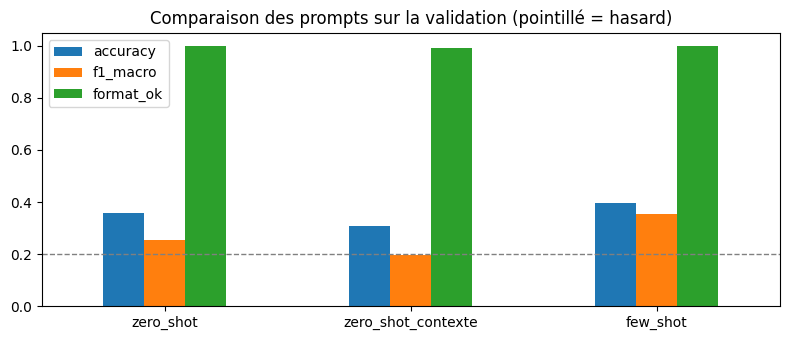

In [9]:
variante_retenue = tab_val["f1_macro"].astype(float).idxmax()
print(f"Prompt retenu (meilleur F1 macro sur la validation) : {variante_retenue}")

ax = tab_val[["accuracy", "f1_macro", "format_ok"]].astype(float).plot.bar(figsize=(8, 3.5), rot=0)
ax.axhline(1 / len(CANDIDATS), color="grey", ls="--", lw=1)
ax.set_title("Comparaison des prompts sur la validation (pointillé = hasard)")
ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

### 5.1 Regarder les sorties brutes

Avant d'interpréter un score, on **lit des sorties** : le format est-il respecté ? le modèle bavarde-t-il ? y a-t-il des biais de prédiction (une classe sur-prédite) ?

In [10]:
detail = sorties_val[variante_retenue]
print("Quelques sorties brutes :\n")
for brut, pred, vrai in list(zip(detail["sortie_brute"], detail["pred"], y_val_eval.values))[:6]:
    print(f"  sortie = {brut!r:55s} -> {pred:15s} (vrai : {vrai})")

print("\nDistribution des prédictions vs distribution réelle (validation) :")
pd.DataFrame({
    "prédit": detail["pred"].value_counts(),
    "réel": y_val_eval.value_counts(),
}).fillna(0).astype(int)

Quelques sorties brutes :

  sortie = '{"locuteur": "MENENIUS"}'                              -> MENENIUS        (vrai : MENENIUS)
  sortie = '{"locuteur": "DUKE VINCENTIO"}'                        -> DUKE VINCENTIO  (vrai : ROMEO)
  sortie = '{"locuteur": "DUKE VINCENTIO"}'                        -> DUKE VINCENTIO  (vrai : PETRUCHIO)
  sortie = '{"locuteur": "DUKE VINCENTIO"}'                        -> DUKE VINCENTIO  (vrai : DUKE VINCENTIO)
  sortie = '{"locuteur": "MENENIUS"}'                              -> MENENIUS        (vrai : ROMEO)
  sortie = '{"locuteur": "DUKE VINCENTIO"}'                        -> DUKE VINCENTIO  (vrai : ROMEO)

Distribution des prédictions vs distribution réelle (validation) :


,prédit,réel
DUKE VINCENTIO,74,25
GLOUCESTER,7,29
MENENIUS,16,19
PETRUCHIO,15,20
ROMEO,2,21


## 6. Évaluation finale sur le test (une seule fois)

On applique **uniquement le prompt retenu** au test, puis on compare avec la baseline **TF-IDF + régression logistique** (ajustée sur le train, même test). Les temps et prompts sont aussi mesurés : un LLM n'a de sens que si son gain de qualité justifie son coût.

LLM (few_shot) : 115 requêtes en 48.6 s (0.42 s/requête) | sorties au bon format : 100.0%

=== Rapport par classe (LLM) ===
                precision    recall  f1-score   support

DUKE VINCENTIO       0.32      0.92      0.47        25
    GLOUCESTER       0.40      0.07      0.11        30
      MENENIUS       0.64      0.47      0.55        19
     PETRUCHIO       0.68      0.65      0.67        20
         ROMEO       1.00      0.19      0.32        21

      accuracy                           0.44       115
     macro avg       0.61      0.46      0.42       115
  weighted avg       0.58      0.44      0.40       115



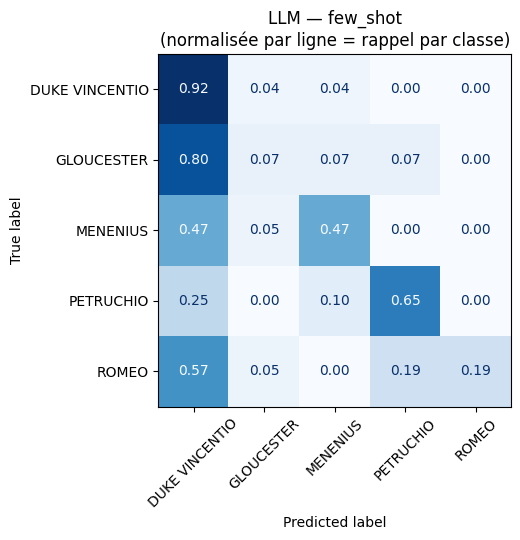

In [11]:
N_TEST = None         # None = tout le test ; un entier pour aller plus vite

X_test_eval = X_test if N_TEST is None else X_test.iloc[:N_TEST]
y_test_eval = y_test.loc[X_test_eval.index]

detail_test, duree_test = predire_llm(X_test_eval.values, variante_retenue)
met_llm = calculer_metriques(y_test_eval.values, detail_test["pred"].values)
print(f"LLM ({variante_retenue}) : {len(detail_test)} requêtes en {duree_test:.1f} s "
      f"({duree_test / len(detail_test):.2f} s/requête) | sorties au bon format : {detail_test['format_ok'].mean():.1%}")

print("\n=== Rapport par classe (LLM) ===")
print(classification_report(y_test_eval.values, detail_test["pred"].values, labels=CANDIDATS, zero_division=0))

etiquettes = CANDIDATS + (["INCONNU"] if (detail_test["pred"] == "INCONNU").any() else [])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(
    y_test_eval.values, detail_test["pred"].values, labels=etiquettes, normalize="true",
    xticks_rotation=45, cmap="Blues", colorbar=False, values_format=".2f", ax=ax)
ax.set_title(f"LLM — {variante_retenue}\n(normalisée par ligne = rappel par classe)")
plt.tight_layout(); plt.show()

In [12]:
# --- Baseline classique : TF-IDF + régression logistique (ajustée sur le train) ---
baseline = Pipeline([
    ("vec", TfidfVectorizer(min_df=2, ngram_range=(1, 2), sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=2000, C=10, class_weight="balanced")),
])
baseline.fit(X_train, y_train)
t0 = time.time()
pred_base = baseline.predict(X_test_eval)
duree_base = time.time() - t0
met_base = calculer_metriques(y_test_eval.values, pred_base)

# Score du meilleur modèle DL du TP2 : recopie ici le F1 macro (test) de TON tableau du TP2 (ou laisse None)
F1_DL_TP2 = None
NOM_DL_TP2 = "Meilleur DL (TP2)"

lignes = {
    "TF-IDF + LogReg (entraîné)": {**met_base, "s_par_requete": duree_base / len(pred_base)},
    f"LLM {variante_retenue} (sans entraînement)": {**met_llm, "s_par_requete": duree_test / len(detail_test)},
}
if F1_DL_TP2 is not None:
    lignes[NOM_DL_TP2] = {"f1_macro": F1_DL_TP2}

comparaison = pd.DataFrame(lignes).T
comparaison.round(4)

,accuracy,precision_macro,recall_macro,f1_macro,s_par_requete
TF-IDF + LogReg (entraîné),0.6348,0.6538,0.6378,0.6415,0.0002
LLM few_shot (sans entraînement),0.4435,0.6084,0.4602,0.4232,0.4229


## 7. Analyse des erreurs

In [13]:
erreurs = detail_test.assign(vrai=y_test_eval.values)
erreurs = erreurs[erreurs["pred"] != erreurs["vrai"]]
print(f"{len(erreurs)} erreurs sur {len(detail_test)} répliques\n")
print("Confusions les plus fréquentes (vrai -> prédit) :")
print(erreurs.groupby(["vrai", "pred"]).size().sort_values(ascending=False).head(6).to_string(), "\n")

erreurs.assign(replique=erreurs["replique"].str.slice(0, 90))[["replique", "sortie_brute", "pred", "vrai"]].head(8)

64 erreurs sur 115 répliques

Confusions les plus fréquentes (vrai -> prédit) :
vrai        pred          
GLOUCESTER  DUKE VINCENTIO    24
ROMEO       DUKE VINCENTIO    12
MENENIUS    DUKE VINCENTIO     9
PETRUCHIO   DUKE VINCENTIO     5
ROMEO       PETRUCHIO          4
PETRUCHIO   MENENIUS           2 



,replique,sortie_brute,pred,vrai
0,"What wilt thou tell her, nurse? thou dost not mark me.","{""locuteur"": ""DUKE VINCENTIO""}",DUKE VINCENTIO,ROMEO
1,"Welcome, dear cousin, my thoughts' sovereign The weary way hath made you melancholy.","{""locuteur"": ""DUKE VINCENTIO""}",DUKE VINCENTIO,GLOUCESTER
3,"Now, my Lord Hastings and Sir William Stanley, Leave off to wonder why I drew you hither,","{""locuteur"": ""DUKE VINCENTIO""}",DUKE VINCENTIO,GLOUCESTER
6,"I say, without characters, fame lives long. Thus, like the formal vice, Iniquity, I morali","{""locuteur"": ""DUKE VINCENTIO""}",DUKE VINCENTIO,GLOUCESTER
11,"A good swift simile, but something currish.","{""locuteur"": ""MENENIUS""}",MENENIUS,PETRUCHIO
12,"I pray thee, chide not; she whom I love now Doth grace for grace and love for love allow;","{""locuteur"": ""DUKE VINCENTIO""}",DUKE VINCENTIO,ROMEO
13,Let me stand here till thou remember it.,"{""locuteur"": ""DUKE VINCENTIO""}",DUKE VINCENTIO,ROMEO
15,Conceives by me! How likes Hortensio that?,"{""locuteur"": ""MENENIUS""}",MENENIUS,PETRUCHIO


In [14]:
# Erreurs selon la longueur de la réplique : peu de mots = peu d'indices, pour le LLM comme pour un classifieur
analyse = pd.DataFrame({
    "n_mots": X_test_eval.str.split().str.len().values,
    "LLM": (detail_test["pred"].values == y_test_eval.values),
    "TF-IDF": (pred_base == y_test_eval.values),
})
analyse["tranche"] = pd.cut(analyse["n_mots"], bins=[0, 10, 20, 40, 1000], labels=["5-10", "11-20", "21-40", ">40"])
analyse.groupby("tranche", observed=True)[["LLM", "TF-IDF"]].mean().round(3)

,LLM,TF-IDF
tranche,,
5-10,0.350,0.425
11-20,0.391,0.652
21-40,0.667,0.875
>40,0.429,0.714


## 8. Variabilité : que se passe-t-il si on active l'échantillonnage ?

À température 0 la sortie est (quasi) déterministe. Dès que la température monte, le même prompt peut donner des réponses différentes : un système en production doit connaître cette **variance**. On relance 3 fois le prompt retenu à température 0,8 sur un sous-ensemble de la validation.

In [15]:
N_VARIAB = min(60, len(X_val_eval))
sous = X_val_eval.iloc[:N_VARIAB]
y_sous = y_val_eval.loc[sous.index].values

f1_t0 = calculer_metriques(y_sous, sorties_val[variante_retenue]["pred"].values[:N_VARIAB])["f1_macro"]
f1_t08 = []
for essai in range(3):
    d, _ = predire_llm(sous.values, variante_retenue, temperature=0.8)
    f1_t08.append(calculer_metriques(y_sous, d["pred"].values)["f1_macro"])

print(f"F1 macro, température 0   : {f1_t0:.3f}")
print(f"F1 macro, température 0,8 : {np.round(f1_t08, 3)}  (moyenne {np.mean(f1_t08):.3f}, écart-type {np.std(f1_t08):.3f})")

F1 macro, température 0   : 0.375
F1 macro, température 0,8 : [0.342 0.281 0.398]  (moyenne 0.340, écart-type 0.048)


## 9. Conclusion

**Ce que ce TP permet de conclure**

1. **Aucune donnée d'entraînement n'est nécessaire pour obtenir un classifieur** : une consigne claire suffit pour dépasser le hasard (20 %). Le LLM, avec le prompt `few_shot`, atteint une accuracy de 0,44 et un F1 macro de 0,42 sur le test. En revanche, il reste **nettement en dessous de la baseline entraînée** (TF-IDF + régression logistique : F1 macro 0,64) et des meilleurs réseaux du TP2 (TextCNN : 0,57).
2. **Un score global cache un fort biais de prédiction.** Le LLM répond presque toujours « DUKE VINCENTIO » (74 prédictions sur 114 en validation, pour 25 répliques réelles) : rappel de 0,92 mais précision de 0,32 pour cette classe, alors que Gloucester n'est presque jamais reconnu (rappel de 0,07) et Romeo très peu (rappel de 0,19, pour une précision de 1,00). Il faut donc toujours lire les résultats par classe et la matrice de confusion, pas seulement l'accuracy.
3. **L'apport du contexte et des exemples** : [compléter avec le tableau du §5, par exemple : « le passage de `zero_shot` à `few_shot` fait passer le F1 macro de X à Y, au prix d'un prompt environ N fois plus long (colonne `tokens_prompt`) »].
4. **Une sortie de LLM se valide.** Le format JSON est respecté dans [X] % des cas (colonne `format_ok`), ce qui rend le parsing fiable ici ; on le vérifie néanmoins systématiquement. De plus, dès que la température n'est plus nulle, les résultats varient d'un tirage à l'autre (F1 macro de 0,29 à 0,43 sur 3 essais à température 0,8) : pour de la classification, on reste à température 0.
5. **Attention à la fuite de données (contamination).** *Tiny Shakespeare* est un texte public très présent dans les corpus de pré-entraînement : le LLM a peut-être déjà vu ces répliques. Son score ne mesure donc pas uniquement une capacité de généralisation et ne serait pas transposable à un corpus privé.
6. **Comparer aussi sur le coût.** Le classifieur TF-IDF répond en une fraction de milliseconde pour un coût négligeable ; le LLM est de plusieurs ordres de grandeur plus lent (voir `s_par_requete` au §6). Pour une tâche étroite à fort volume, le pipeline classique reste le bon choix ; le LLM est plus pertinent pour le langage ouvert, la génération, ou comme brique d'un système hybride.

**Pour aller plus loin** : un modèle plus grand ou une API, un autre ordre des noms dans le prompt (pour tester le biais vers le premier de la liste), plus d'exemples, ou un fine-tuning léger (LoRA) sur le train.